# Data Cleaning & Visualization Project
**Goal:** take a raw, messy retail-orders dataset, clean it (missing values, outliers, duplicates, inconsistent formats), visualise it, and tell the story behind the data.

**Pipeline:** `raw CSV` -> *audit* -> *clean* -> *validate* -> *explore* -> *insights*

All reusable logic lives in `src/clean_data.py` and `src/visualize.py`; this notebook walks through it step by step.

In [1]:
import sys; sys.path.insert(0, "../src")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
import clean_data as cd, visualize as viz

pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

## 1. Load & audit the raw data
Everything is read as text first, so nothing is silently guessed at load time.

In [2]:
raw = cd.load_raw()
print(raw.shape)
raw.head(8)

(4278, 14)


,order_id,order_date,customer_name,customer_age,region,category,product,quantity,unit_price,discount,payment_method,delivery_days,sales,rating
0,ORD-100544,01/11/2024,Sneha Nair,NaN,East,Sports,Football,1,25.94,0.05,Net Banking,5,24.64,4.0
1,ORD-100410,2023-11-07,Arjun Kumar,33,South,Sports,Tennis Racket,2,79.83,0.0,Debit Card,5,159.66,5.0
2,ORD-102555,2024-07-11,Priya Menon,18,East,Electronics,Webcam,2,41.54,0.0,Debit Card,6,83.08,4.5
3,ORD-101281,16/08/2024,Divya Das,34,West,ELECTRONICS,Headphones,3,54.29,NaN,Credit Card,NaN,$162.87,3.0
4,ORD-100598,02-Jun-2023,rohan iyer,48,NORTH,Clothing,T-Shirt,2,14.7,0.15,Net Banking,6,24.99,3.5
5,ORD-102196,2023-10-01,Aditya Das,37,NaN,Clothing,Jacket,3,94.34,0.05,UPI,3,268.87,NaN
6,ORD-102456,2024-04-05,Pooja Nair,45,WEST,Books,Comic,1,8.44,0.15,net banking,2,7.17,5.0
7,ORD-103554,2023-11-07,Siddharth Sharma,29,South,CLOTHING,T-Shirt,3,16.87,0.1,CASH ON DELIVERY,2,45.55,4.5


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 4278 entries, 0 to 4277
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   order_id        4278 non-null   str  
 1   order_date      4278 non-null   str  
 2   customer_name   4184 non-null   str  
 3   customer_age    3993 non-null   str  
 4   region          4106 non-null   str  
 5   category        4278 non-null   str  
 6   product         4237 non-null   str  
 7   quantity        4278 non-null   str  
 8   unit_price      4278 non-null   str  
 9   discount        4070 non-null   str  
 10  payment_method  4160 non-null   str  
 11  delivery_days   4093 non-null   str  
 12  sales           4278 non-null   str  
 13  rating          3858 non-null   str  
dtypes: str(14)
memory usage: 468.0 KB


### What is wrong with it? (data-quality audit)

In [4]:
audit = cd.audit(raw)
print(f"Rows: {audit['rows']:,}")
print(f"Exact duplicate rows: {audit['exact_duplicate_rows']}")
print(f"Total missing cells (incl. blanks and 'N/A'): {audit['missing_total']:,}")
pd.Series(audit["missing_by_column"], name="missing").sort_values(ascending=False).to_frame()

Rows: 4,278
Exact duplicate rows: 164
Total missing cells (incl. blanks and 'N/A'): 1,548


,missing
rating,420
customer_age,285
discount,208
delivery_days,185
region,172
payment_method,118
customer_name,94
product,41
category,25
order_date,0


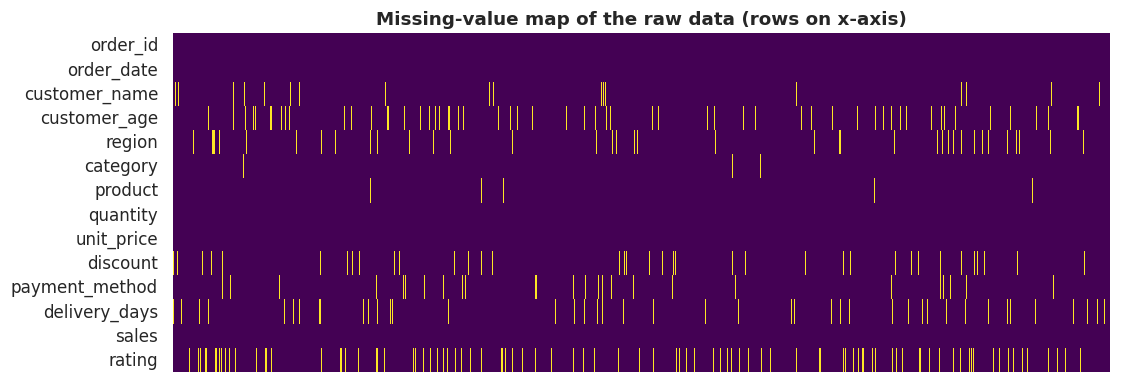

In [5]:
# Visual: where are the gaps?  (each yellow line = a missing cell)
tmp, _ = cd.standardize_text(raw)
plt.figure(figsize=(11, 4))
sns.heatmap(tmp.isna().T, cbar=False, cmap="viridis", xticklabels=False)
plt.title("Missing-value map of the raw data (rows on x-axis)"); plt.show()

In [6]:
# Inconsistent labels - the same region written many different ways
print(raw["region"].value_counts(dropna=False).head(20))

region
South       722
West        638
North       589
East        554
Central     289
NaN         172
west        109
SOUTH       104
south       101
WEST         96
east         87
  West       83
NORTH        81
EAST         77
north        76
  South      72
  North      69
  East       64
W.           63
S.           56
Name: count, dtype: int64


## 2. Cleaning, step by step
### 2.1 Standardise text
Trim whitespace, unify case, map abbreviations (`N.` -> `North`, `COD` -> `Cash on Delivery`), turn `N/A` and blanks into real missing values.

In [7]:
df, info = cd.standardize_text(raw)
print(info)
df["region"].value_counts(dropna=False)

{'unique_labels_before': {'region': 19, 'category': 17, 'payment_method': 16}, 'unique_labels_after': {'region': 5, 'category': 5, 'payment_method': 5}}


region
South      1055
West        989
North       850
East        820
Central     392
<NA>        172
Name: count, dtype: Int64

### 2.2 Fix data types
Four different date formats and `$1,234.50`-style text in the numeric `sales` column.

In [8]:
df, info = cd.parse_types(df)
print(info)
df[["order_date", "sales"]].dtypes

{'sales_values_with_currency_symbols': 348, 'unparseable_dates': 0}


order_date    datetime64[us]
sales                float64
dtype: object

### 2.3 Remove duplicates
Exact copies are dropped; if the same `order_id` still appears twice we keep the *most complete* record.

In [9]:
n_before = len(df)
df, info = cd.remove_duplicates(df)
print(info, f"| {n_before:,} -> {len(df):,} rows")

{'exact_duplicates_removed': 164, 'same_order_id_removed': 0, 'rows_after': 4114} | 4,278 -> 4,114 rows


### 2.4 Detect & treat outliers
Two complementary methods:
1. **IQR rule (1.5 x IQR)** - a statistical *detector*.
2. **Domain rules** - e.g. nobody is 250 years old, nobody orders 150 headphones, a `$35 T-shirt` is not `$525`.

Statistical outliers are not always errors, so values are only changed when the domain rules say they are impossible.

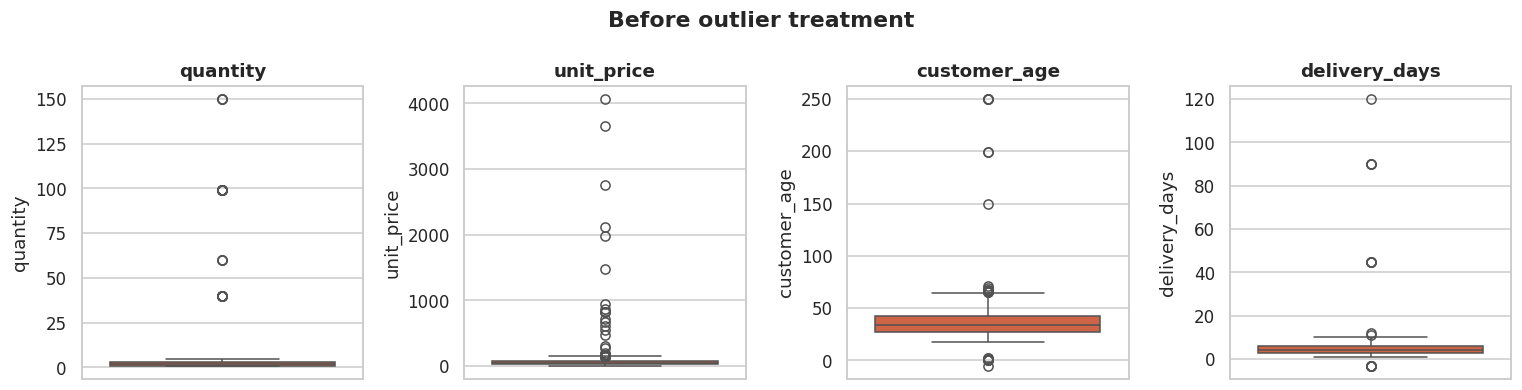

{'quantity': 25, 'unit_price': 79, 'customer_age': 24, 'delivery_days': 16}

In [10]:
num = ["quantity", "unit_price", "customer_age", "delivery_days"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, c in zip(axes, num):
    sns.boxplot(y=df[c], ax=ax, color="#E4572E"); ax.set_title(c)
fig.suptitle("Before outlier treatment", fontweight="bold"); plt.tight_layout(); plt.show()
{c: cd.count_iqr_outliers(df[c]) for c in num}

In [11]:
df, info = cd.handle_invalid_and_outliers(df)
info

{'customer_age_out_of_range': 15,
 'delivery_days_out_of_range': 14,
 'discount_out_of_range': 0,
 'rating_out_of_range': 0,
 'quantity_out_of_range': 25,
 'unit_price_extreme': 20}

### 2.5 Impute missing values
| Column | Strategy | Why |
|---|---|---|
| category | infer from `product` | a product always belongs to one category |
| region, payment, name, product | `Unknown` | inventing a value would bias results |
| quantity, unit_price | median per product | robust to skew |
| customer_age | median per category | robust to skew |
| delivery_days | median per region | |
| discount | 0 | the most common value (no discount) |
| rating | median per delivery-days | rating depends on delivery speed |
| sales | recomputed = qty x price x (1 - discount) | keeps the data internally consistent |

In [12]:
df, info = cd.impute_missing(df)
print("Missing cells left:", int(df.isna().sum().sum()))
info

Missing cells left: 0


{'sales_recomputed': 156,
 'filled_customer_name': 90,
 'filled_customer_age': 290,
 'filled_region': 163,
 'filled_category': 25,
 'filled_product': 40,
 'filled_quantity': 25,
 'filled_discount': 199,
 'filled_payment_method': 116,
 'filled_delivery_days': 194,
 'filled_rating': 401}

### 2.6 Feature engineering & save

In [13]:
df = cd.add_features(df)
df.to_csv(cd.CLEAN_PATH, index=False)
df.head()

,order_id,order_date,customer_name,customer_age,region,category,product,quantity,unit_price,discount,payment_method,delivery_days,sales,rating,outlier_adjusted,year,month,quarter,year_month,age_group,is_discounted
0,ORD-101993,2023-01-01,Siddharth Sharma,47,South,Home & Kitchen,Coffee Maker,1,63.52,0.15,Debit Card,1,53.99,5.0,False,2023,1,Q1,2023-01,45-54,True
1,ORD-103018,2023-01-01,Rahul Nair,33,West,Home & Kitchen,Vacuum Cleaner,2,141.99,0.05,UPI,4,269.78,3.0,False,2023,1,Q1,2023-01,25-34,True
2,ORD-101839,2023-01-01,Kavya Reddy,25,West,Clothing,Hoodie,1,41.70,0.00,Unknown,8,41.70,3.5,False,2023,1,Q1,2023-01,25-34,False
3,ORD-101888,2023-01-01,Lakshmi Sharma,36,East,Electronics,Power Bank,1,27.60,0.15,UPI,1,23.46,4.5,False,2023,1,Q1,2023-01,35-44,True
4,ORD-101212,2023-01-01,Lakshmi Reddy,30,Central,Books,Textbook,1,52.56,0.15,UPI,4,44.68,4.5,False,2023,1,Q1,2023-01,25-34,True


## 3. Validate the result
Check - not assume - that cleaning worked.

In [14]:
clean, log = cd.run_cleaning()      # same pipeline in one call; also writes reports/cleaning_report.md
checks = {
    "no missing values": clean.isna().sum().sum() == 0,
    "no duplicate rows": not clean.duplicated().any(),
    "no duplicate order ids": clean["order_id"].is_unique,
    "age between 16 and 90": clean["customer_age"].between(16, 90).all(),
    "quantity between 1 and 10": clean["quantity"].between(1, 10).all(),
    "sales = qty*price*(1-discount)": np.allclose(clean["sales"], (clean["quantity"]*clean["unit_price"]*(1-clean["discount"])).round(2)),
    "dates are datetime & in 2023-2024": pd.to_datetime(clean["order_date"]).between("2023-01-01", "2024-12-31").all(),
}
pd.Series(checks, name="passed").to_frame()

,passed
no missing values,True
no duplicate rows,True
no duplicate order ids,True
age between 16 and 90,True
quantity between 1 and 10,True
sales = qty*price*(1-discount),True
dates are datetime & in 2023-2024,True


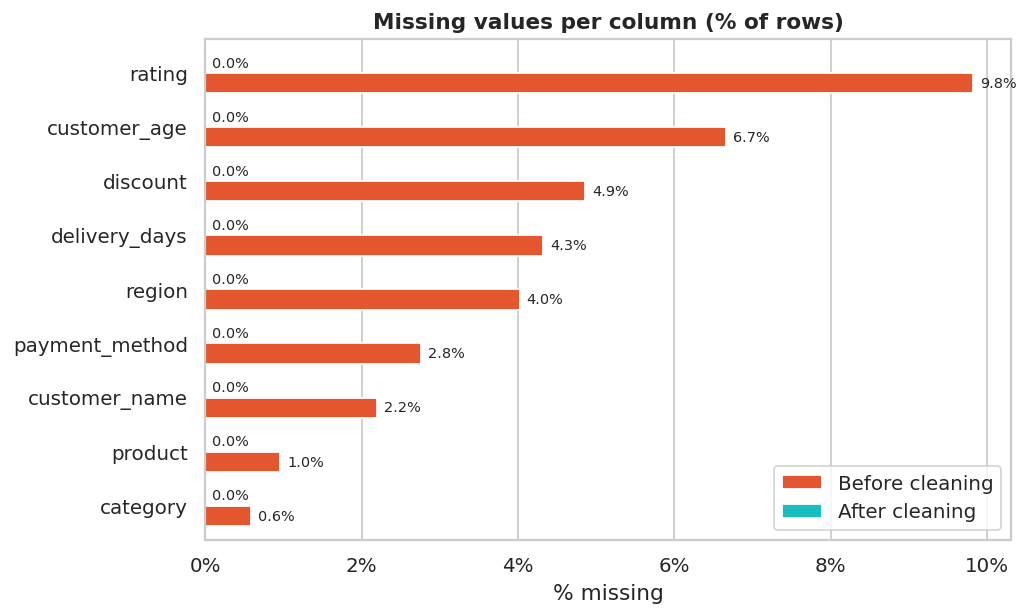

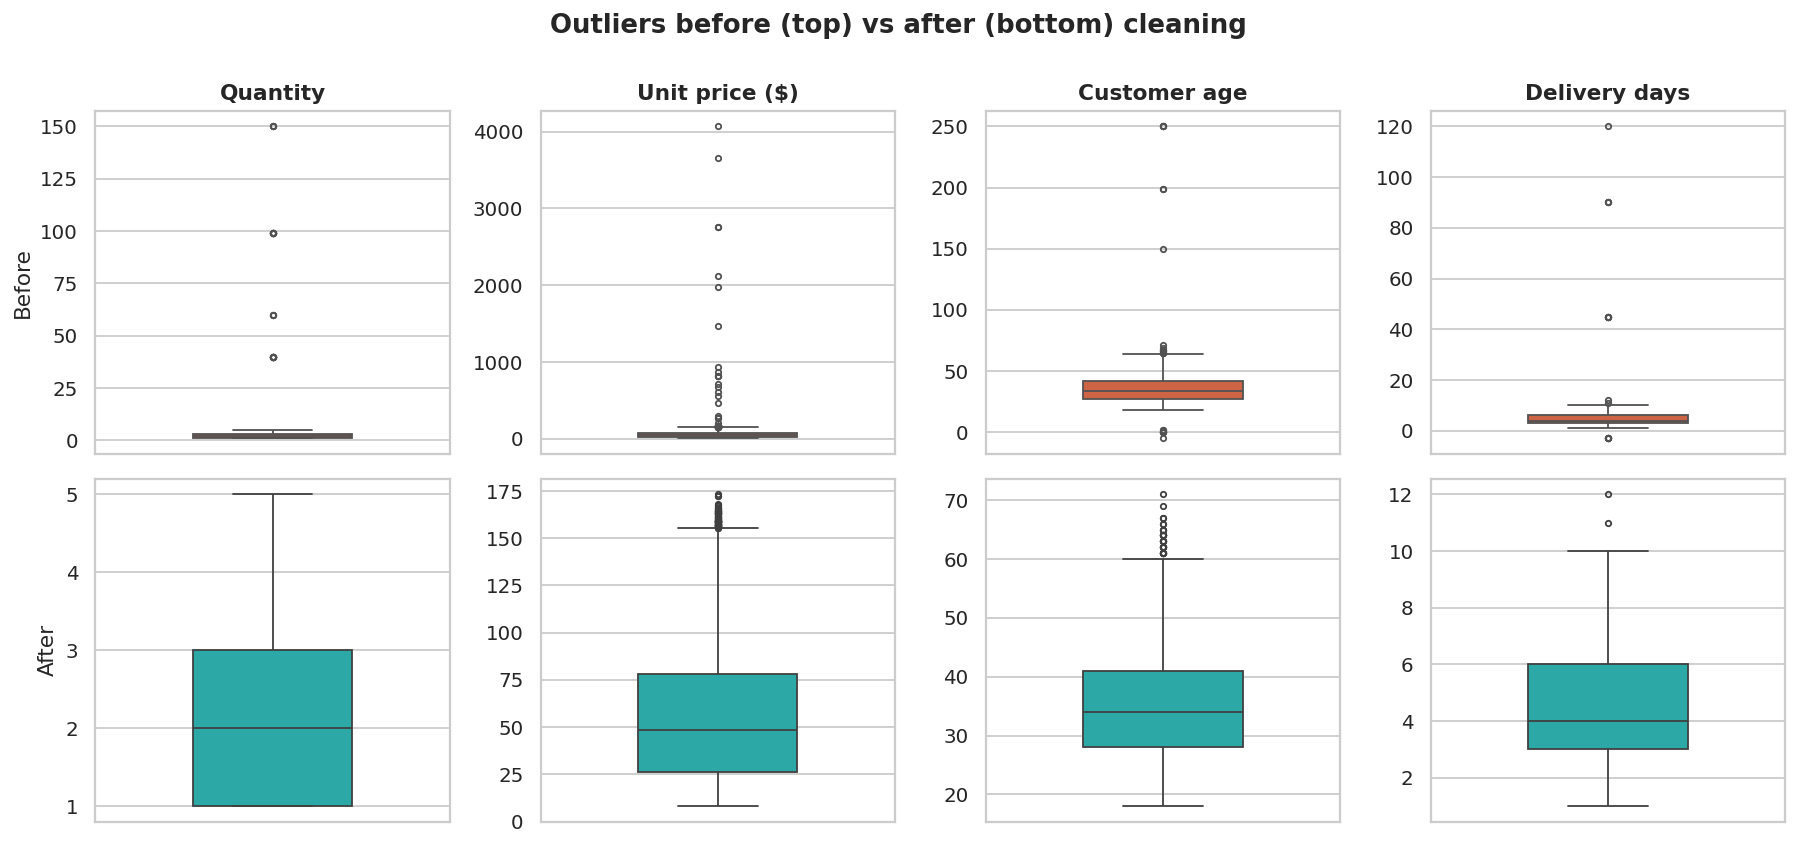

In [15]:
raw_parsed = viz.load_raw_parsed()
clean = viz.load_clean()
display(Image(viz.plot_missing_before_after(raw_parsed, clean)))
display(Image(viz.plot_outliers_before_after(raw_parsed, clean)))

In [16]:
print(open("../reports/cleaning_report.md").read())

# Data Cleaning Report

| Metric | Before | After |
|---|---:|---:|
| Rows | 4,278 | 4,114 |
| Exact duplicate rows | 164 | 0 |
| Duplicate order IDs | 164 | 0 |
| Missing cells | 1,548 | 0 |

## Step by step

1. **Standardise text** - trimmed whitespace, unified case, mapped abbreviations (unique labels before -> after: {'region': 19, 'category': 17, 'payment_method': 16} -> {'region': 5, 'category': 5, 'payment_method': 5}).
2. **Fix data types** - parsed 4 mixed date formats (0 unparseable); stripped currency symbols from 348 `sales` values.
3. **Remove duplicates** - 164 exact duplicates and 0 repeated order IDs removed.
4. **Invalid values & outliers** - customer age out of range: 15, delivery days out of range: 14, discount out of range: 0, rating out of range: 0, quantity out of range: 25, unit price extreme: 20.
5. **Missing values** - customer_name: 90, customer_age: 290, region: 163, category: 25, product: 40, quantity: 25, discount: 199, payment_method: 116, delivery_days: 1

## 4. Exploratory analysis & visualisation

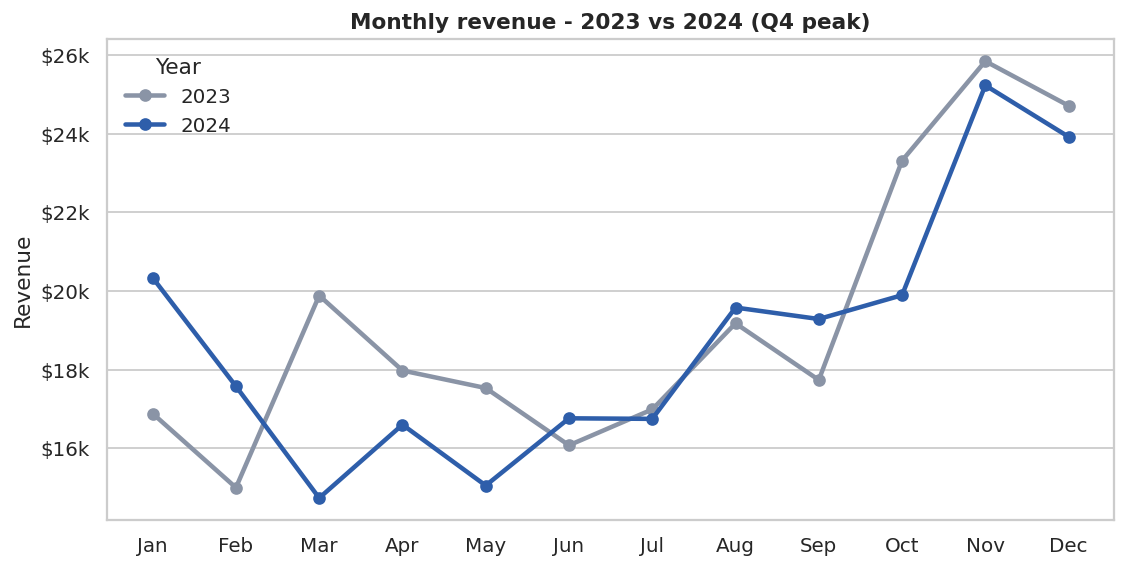

In [17]:
display(Image(viz.plot_monthly_revenue(clean)))

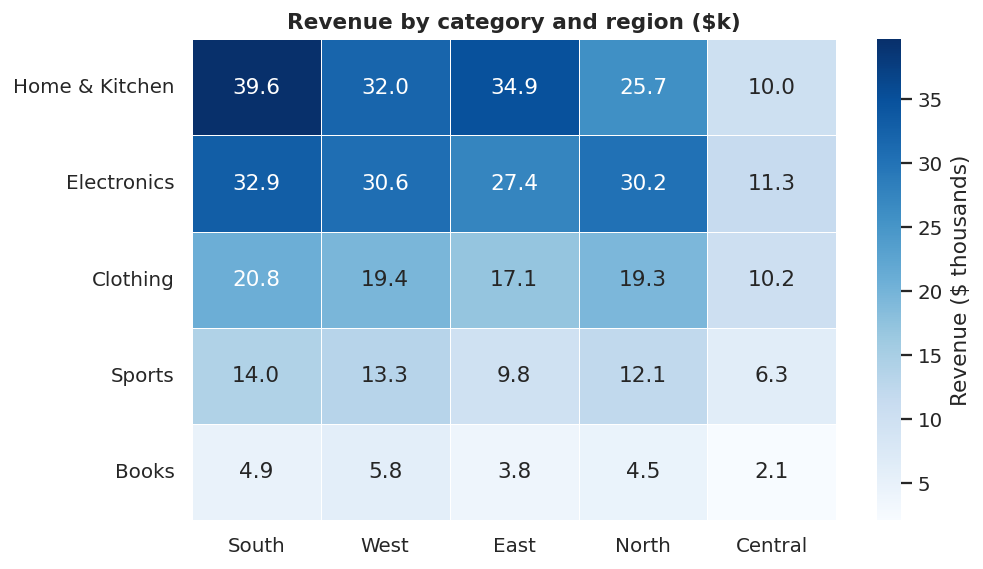

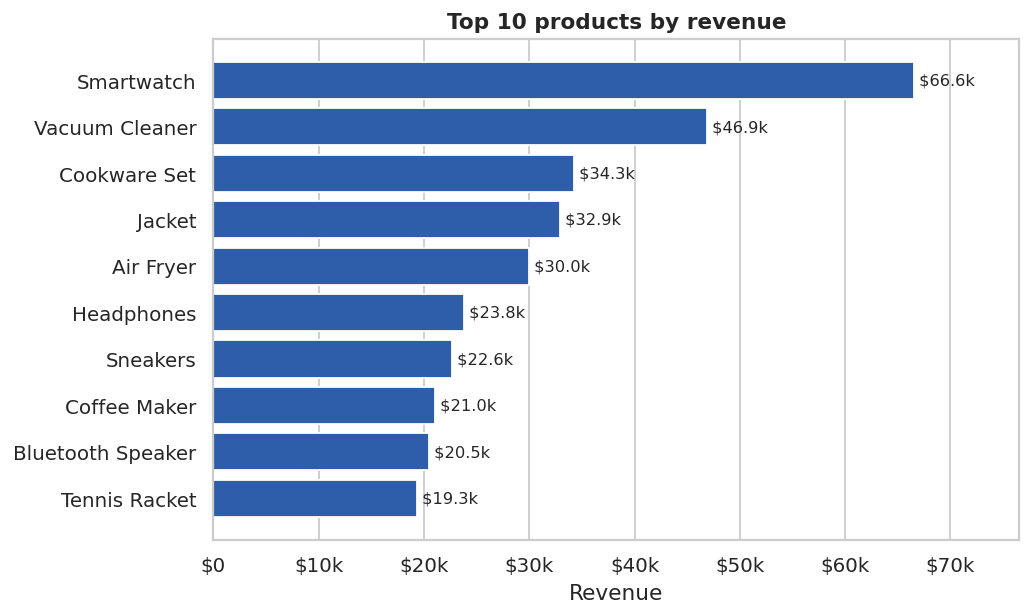

In [18]:
display(Image(viz.plot_category_region_heatmap(clean)))
display(Image(viz.plot_top_products(clean)))

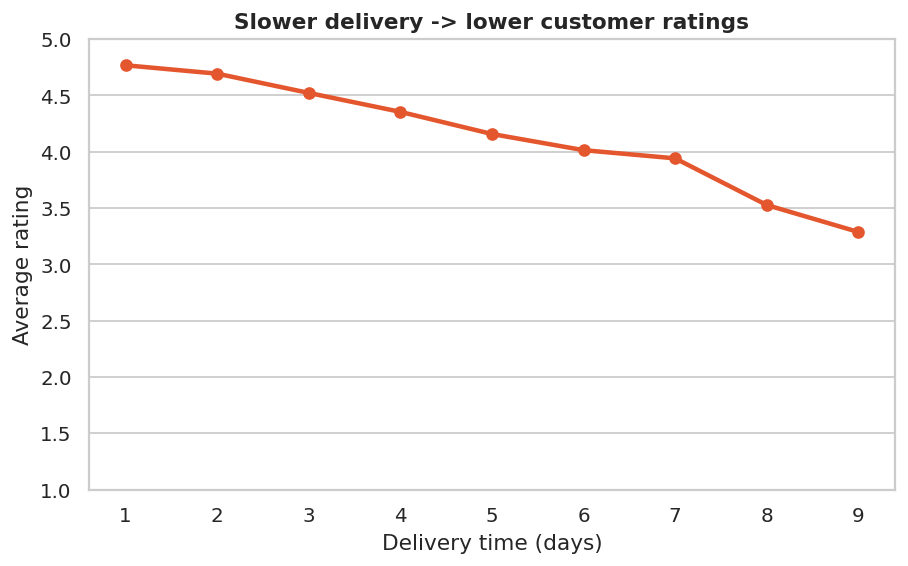

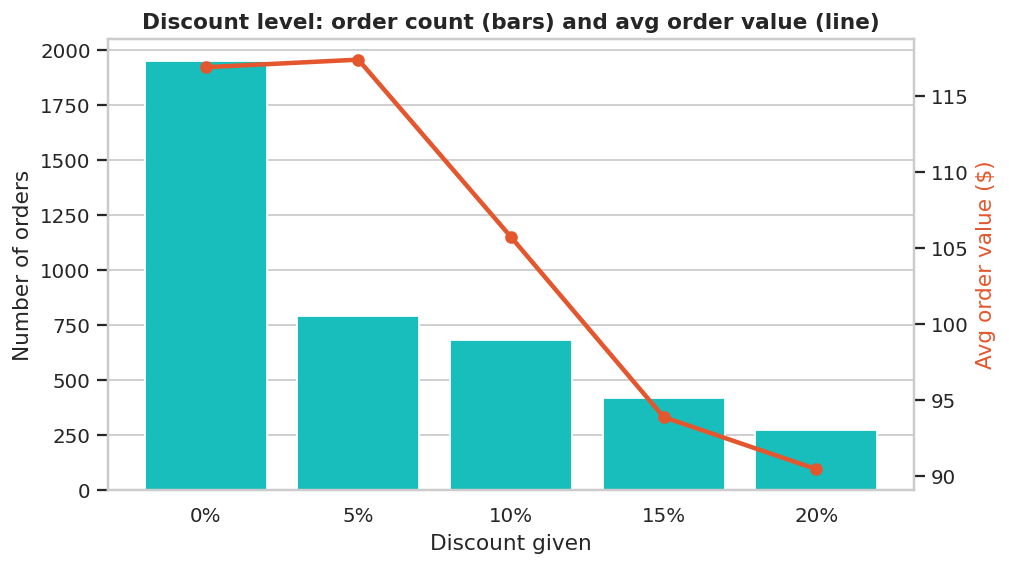

In [19]:
display(Image(viz.plot_rating_vs_delivery(clean)))
display(Image(viz.plot_discount_effect(clean)))

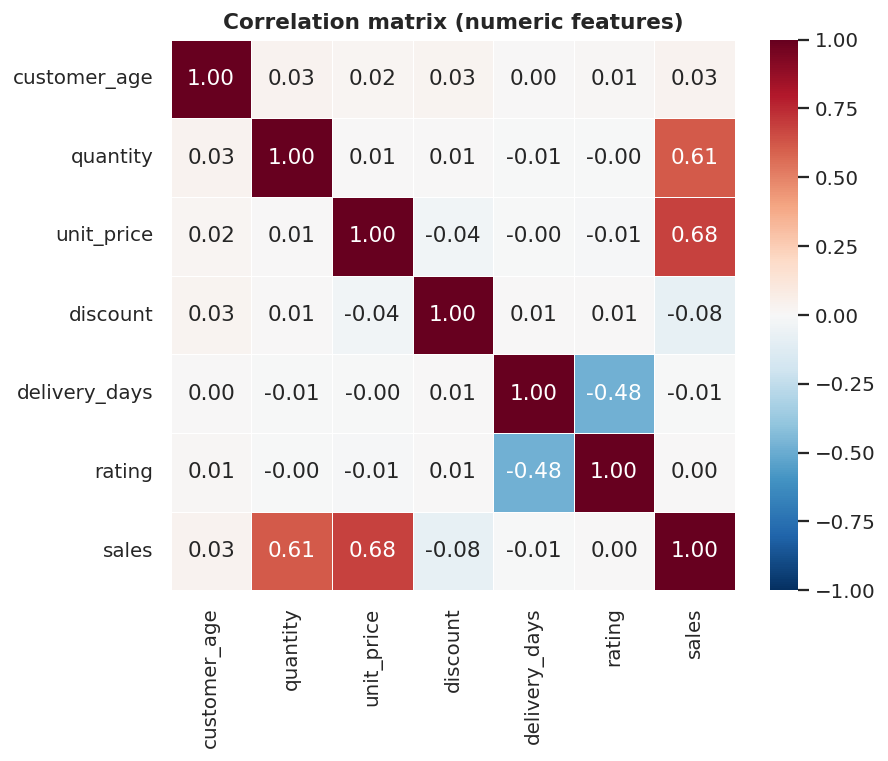

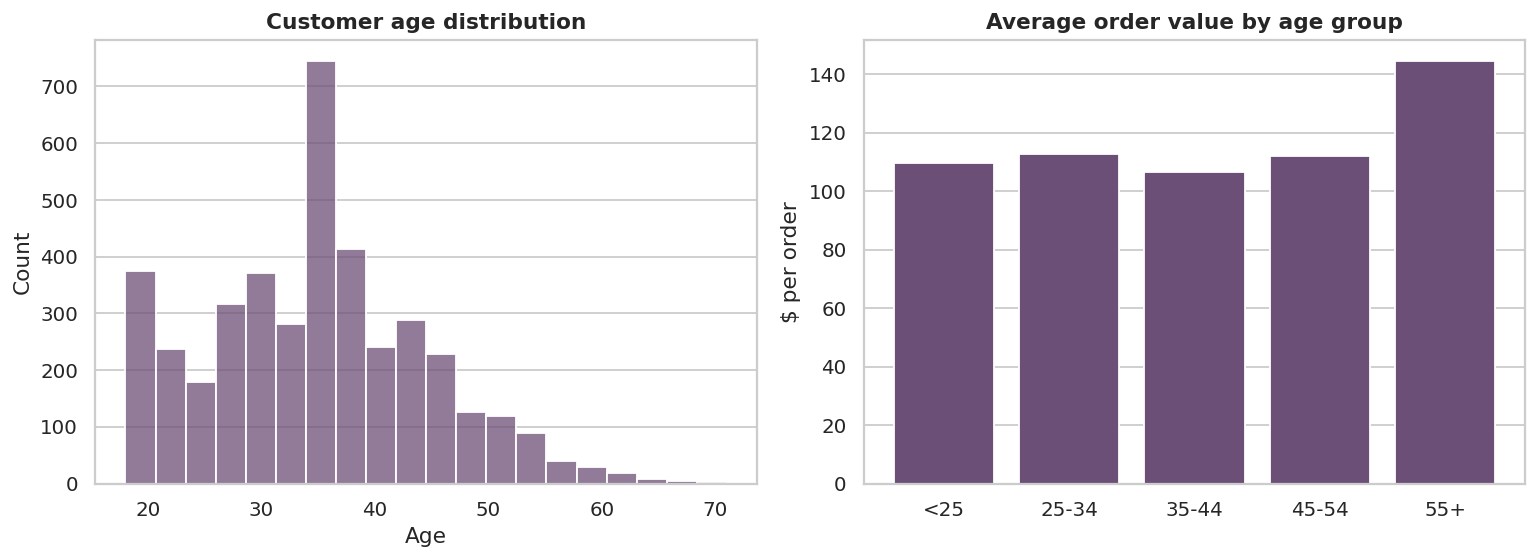

In [20]:
display(Image(viz.plot_correlation(clean)))
display(Image(viz.plot_customer_profile(clean)))

## 5. Dashboard

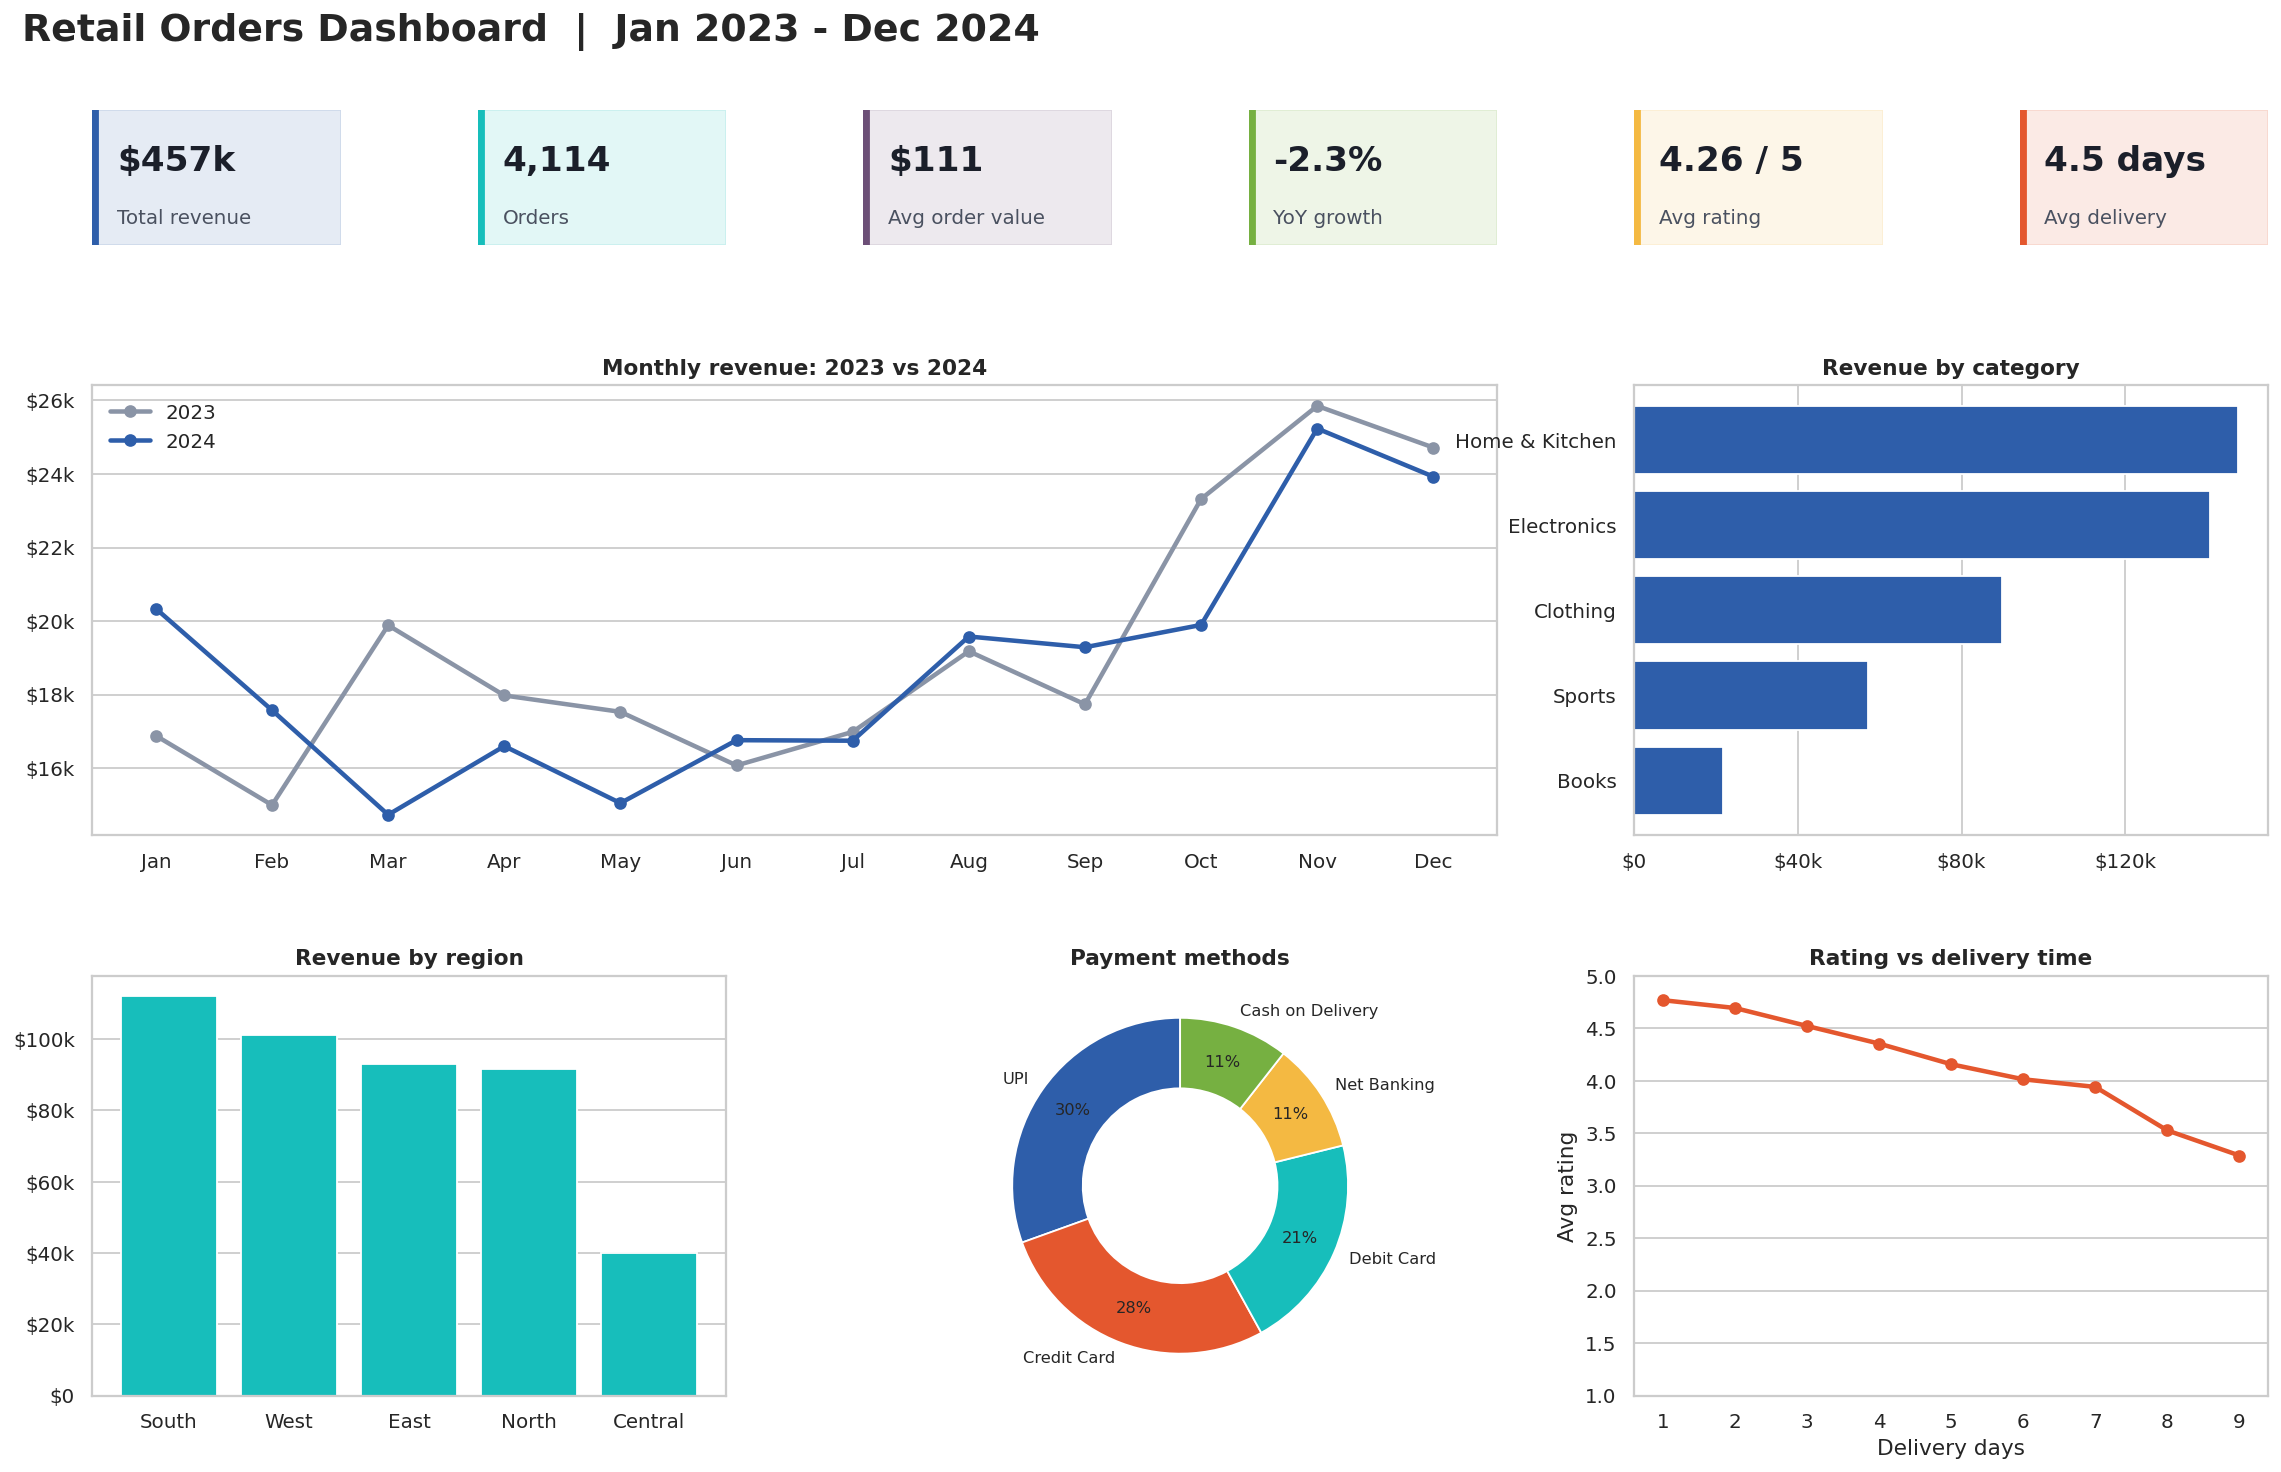

In [21]:
ins = viz.compute_insights(clean)
display(Image(viz.build_dashboard(clean, ins)))

## 6. Insights - the story the data tells

In [22]:
from IPython.display import Markdown
Markdown("\n".join(f"{n}. {s}" for n, s in enumerate(viz.insight_sentences(ins), 1)))

1. Revenue declined 2.3% year over year ($231,139 in 2023 vs $225,731 in 2024) - growth is flat, so new demand levers are needed.
2. Q4 (Oct-Dec) alone brings 31.3% of annual revenue (25% would be an even split) - stock and campaigns should peak before October.
3. Home & Kitchen is the strongest category (32.3% of revenue); Books is the smallest (4.7%).
4. South leads the regions while Central is the weakest - a clear target for regional campaigns.
5. Delivery speed drives satisfaction: orders delivered in 3 days or less average a 4.61 rating vs 3.78 for 7+ days (correlation -0.48).
6. UPI is the most used payment method (30.5% of orders).
7. Discounted orders average $106 vs $117 at full price: discounts do not lift basket size, so their profitability should be tested.
8. 'Smartwatch' is the best-selling product by revenue ($66,571).

## 7. Conclusion
- The raw file looked usable but hid duplicates, impossible values, inconsistent labels, text-typed numbers, mixed date formats and gaps in about a third of its columns.
- After cleaning, every validation check passes and the dataset can be trusted for analysis.
- The analysis highlights a strong Q4 season, a clear gap between regions and categories, and a strong link between delivery time and customer satisfaction.
- **Next steps:** add profit margin data, test discount profitability, forecast monthly revenue, and investigate the weak Central region.